In [1]:
from google.colab import files
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import csv
data = pd.read_csv('/content/Day-07_water_potability.csv', quoting=csv.QUOTE_NONE)

In [3]:
data.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [4]:
data.tail()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
3271,4.668102,193.681735,47580.991603,7.166639,359.948574,526.424171,13.894419,66.687695,4.435821,1
3272,7.808856,193.553212,17329.802160,8.061362,NaN,392.449580,19.903225,NaN,2.798243,1
3273,9.419510,175.762646,33155.578218,7.350233,NaN,432.044783,11.039070,69.845400,3.298875,1
3274,5.126763,230.603758,11983.869376,6.303357,NaN,402.883113,11.168946,77.488213,4.708658,1
3275,7.874671,195.102299,17404.177061,7.509306,NaN,327.459760,16.140368,78.698446,2.309149,1


In [5]:
data.shape

(3276, 10)

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


In [7]:
data.describe()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


In [8]:
data.min(numeric_only=True)

,0
ph,0.000000
Hardness,47.432000
Solids,320.942611
Chloramines,0.352000
Sulfate,129.000000
Conductivity,181.483754
Organic_carbon,2.200000
Trihalomethanes,0.738000
Turbidity,1.450000
Potability,0.000000


In [9]:
data.max(numeric_only=True)

,0
ph,14.000000
Hardness,323.124000
Solids,61227.196008
Chloramines,13.127000
Sulfate,481.030642
Conductivity,753.342620
Organic_carbon,28.300000
Trihalomethanes,124.000000
Turbidity,6.739000
Potability,1.000000


In [10]:
data['Hardness'].unique()

array([204.89045547, 129.42292051, 224.23625939, ..., 175.7626463 ,
       230.60375751, 195.10229859], shape=(3276,))

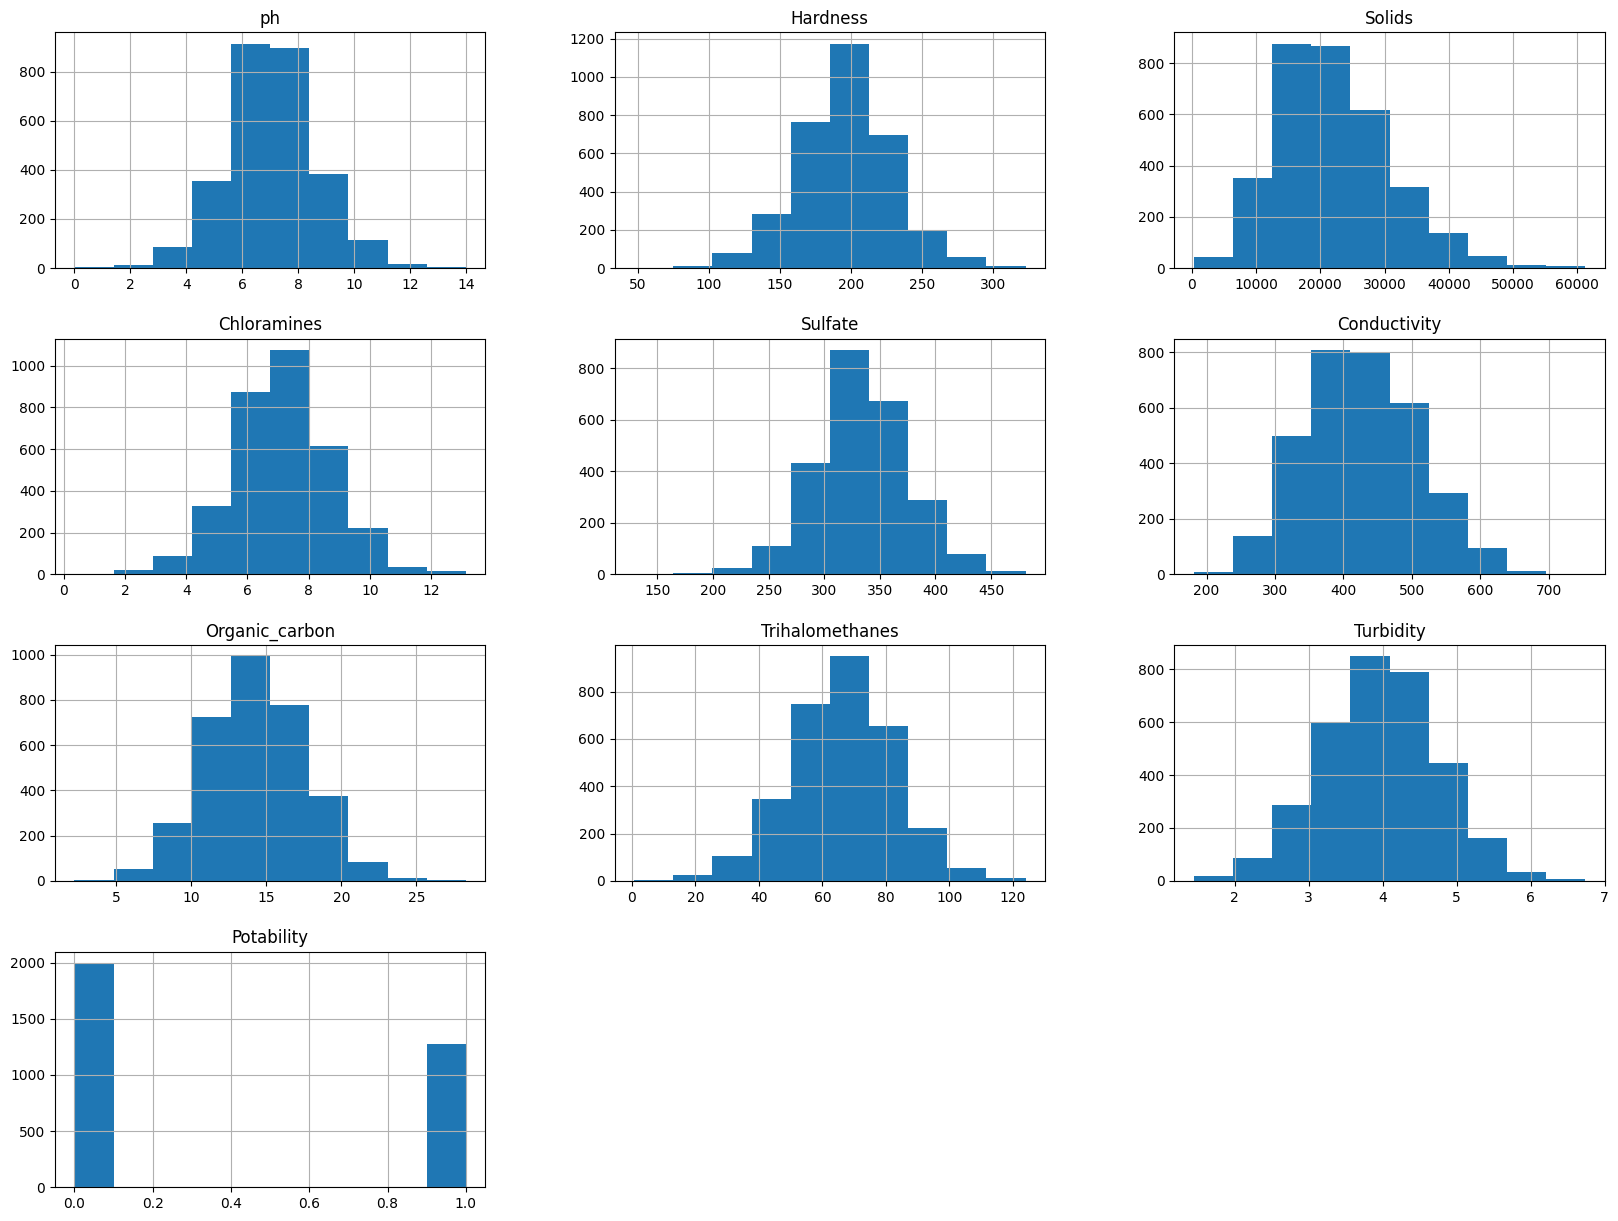

In [11]:
data.hist(figsize=(20, 15))
plt.show()

<Axes: >

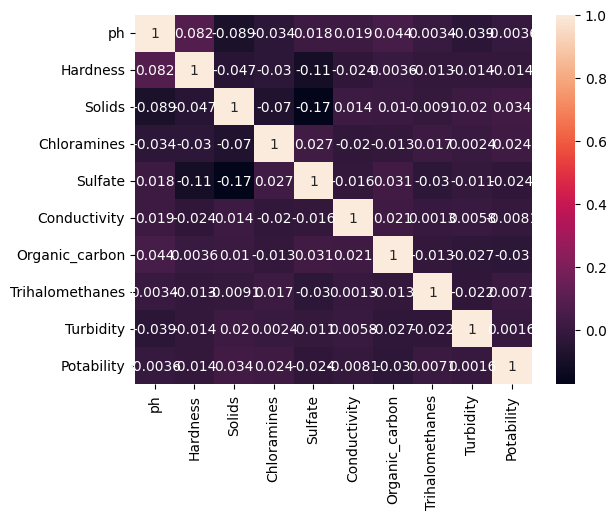

In [12]:
sns.heatmap(data.corr(numeric_only=True), annot=True)

In [13]:
c = data.corr(numeric_only=True).abs()
pairs = c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack()
print(pairs.sort_values(ascending=False).head(15))

Solids          Sulfate            0.171804
Hardness        Sulfate            0.106923
ph              Solids             0.089288
                Hardness           0.082096
Solids          Chloramines        0.070148
Hardness        Solids             0.046899
ph              Organic_carbon     0.043503
                Turbidity          0.039057
                Chloramines        0.034350
Solids          Potability         0.033743
Sulfate         Organic_carbon     0.030831
                Trihalomethanes    0.030274
Hardness        Chloramines        0.030054
Organic_carbon  Potability         0.030001
                Turbidity          0.027308
dtype: float64


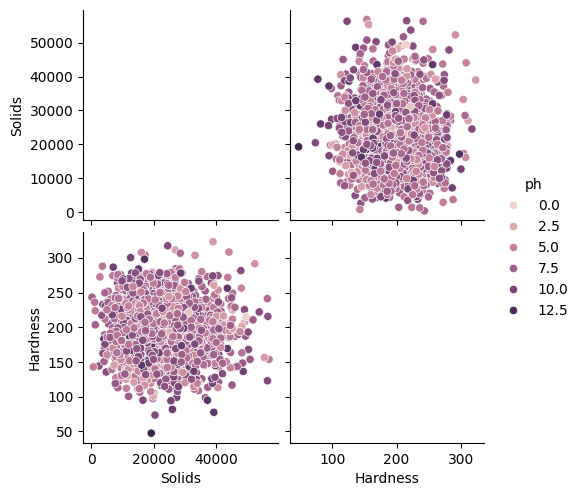

In [15]:
sns.pairplot(data[['Solids', 'Hardness', 'ph']].dropna(), hue='ph')
plt.show()

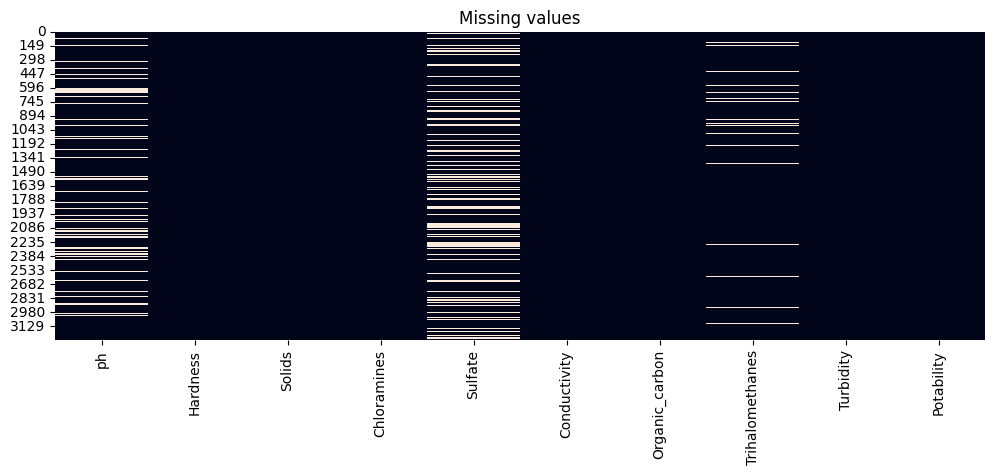

In [16]:
plt.figure(figsize=(12,4))
sns.heatmap(data.isna(), cbar=False)
plt.title("Missing values")
plt.show()

--- Missing Values Information ---
                 Missing Values  Percentage (%)
ph                          491       14.987790
Sulfate                     781       23.840049
Trihalomethanes             162        4.945055

--- Potability Class Distribution ---
Potability
0    1998
1    1278
Name: count, dtype: int64


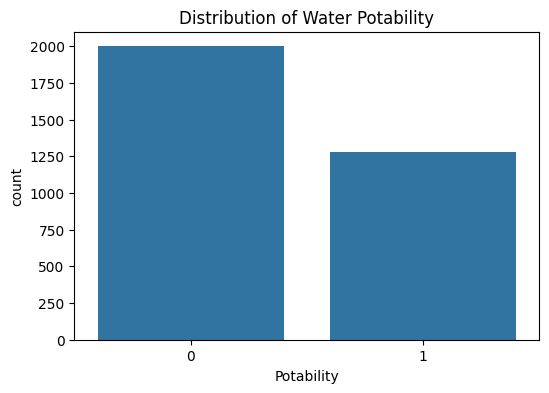

In [18]:
missing_count = data.isnull().sum()
missing_percentage = (data.isnull().sum() / len(data)) * 100
missing_info = pd.DataFrame({'Missing Values': missing_count, 'Percentage (%)': missing_percentage})
print("--- Missing Values Information ---")
print(missing_info[missing_info['Missing Values'] > 0])

print("\n--- Potability Class Distribution ---")
print(data['Potability'].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(data=data, x='Potability')
plt.title('Distribution of Water Potability')
plt.show()

--- Mean values grouped by Potability ---
                  ph    Hardness        Solids  Chloramines    Sulfate  \
Potability                                                               
0           7.085378  196.733292  21777.490788     7.092175  334.56429   
1           7.073783  195.800744  22383.991018     7.169338  332.56699   

            Conductivity  Organic_carbon  Trihalomethanes  Turbidity  
Potability                                                            
0             426.730454       14.364335        66.303555   3.965800  
1             425.383800       14.160893        66.539684   3.968328  


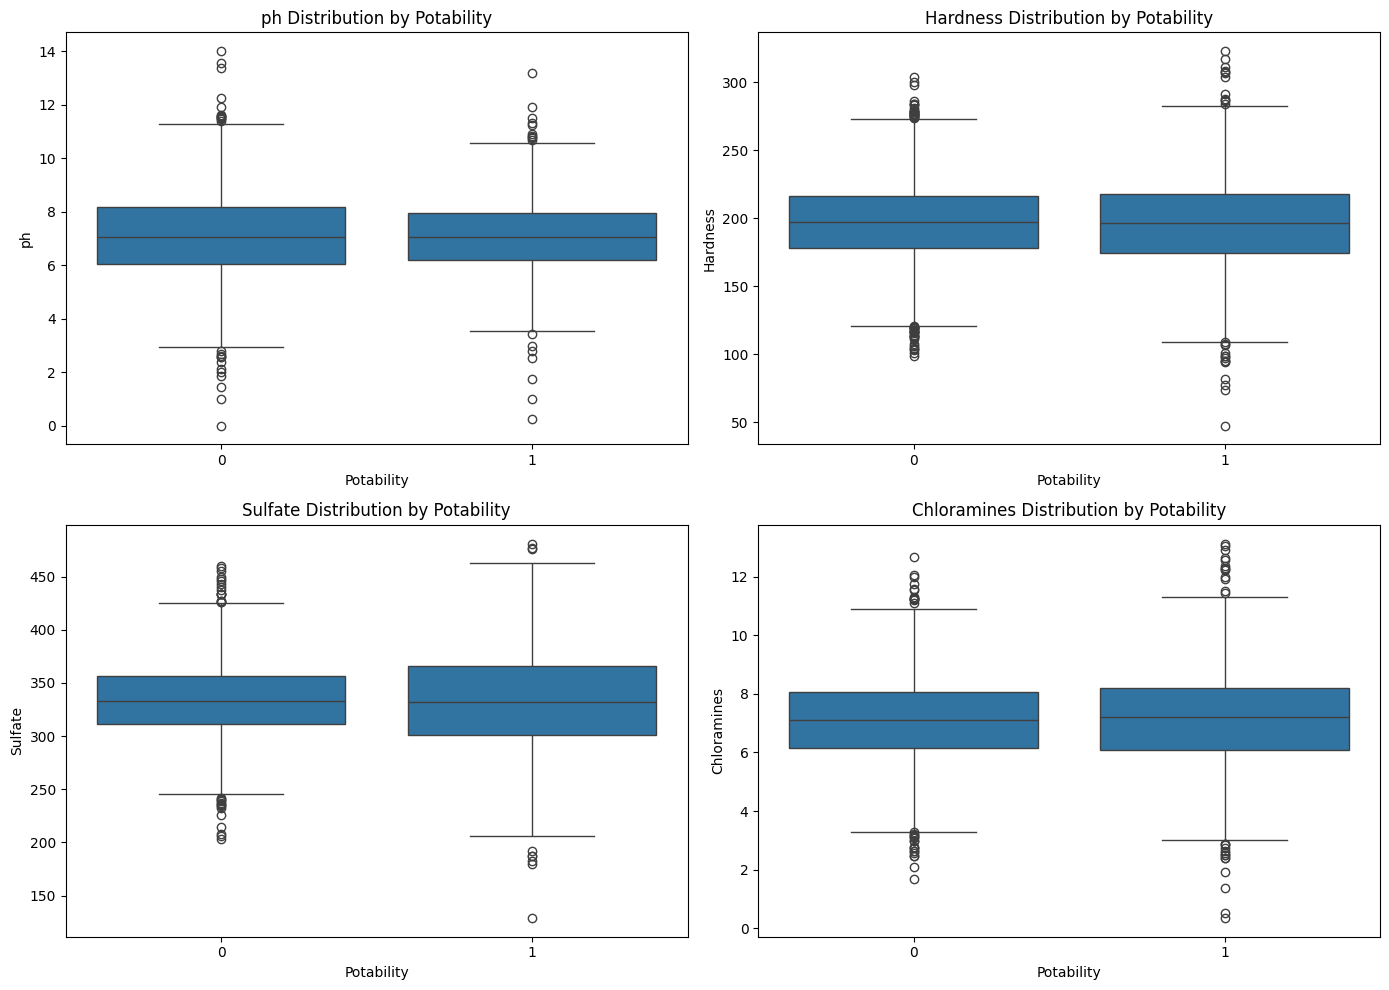

In [19]:
print("--- Mean values grouped by Potability ---")
print(data.groupby('Potability').mean(numeric_only=True))

features_to_plot = ['ph', 'Hardness', 'Sulfate', 'Chloramines']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(features_to_plot):
    sns.boxplot(data=data, x='Potability', y=col, ax=axes[i])
    axes[i].set_title(f'{col} Distribution by Potability')

plt.tight_layout()
plt.show()

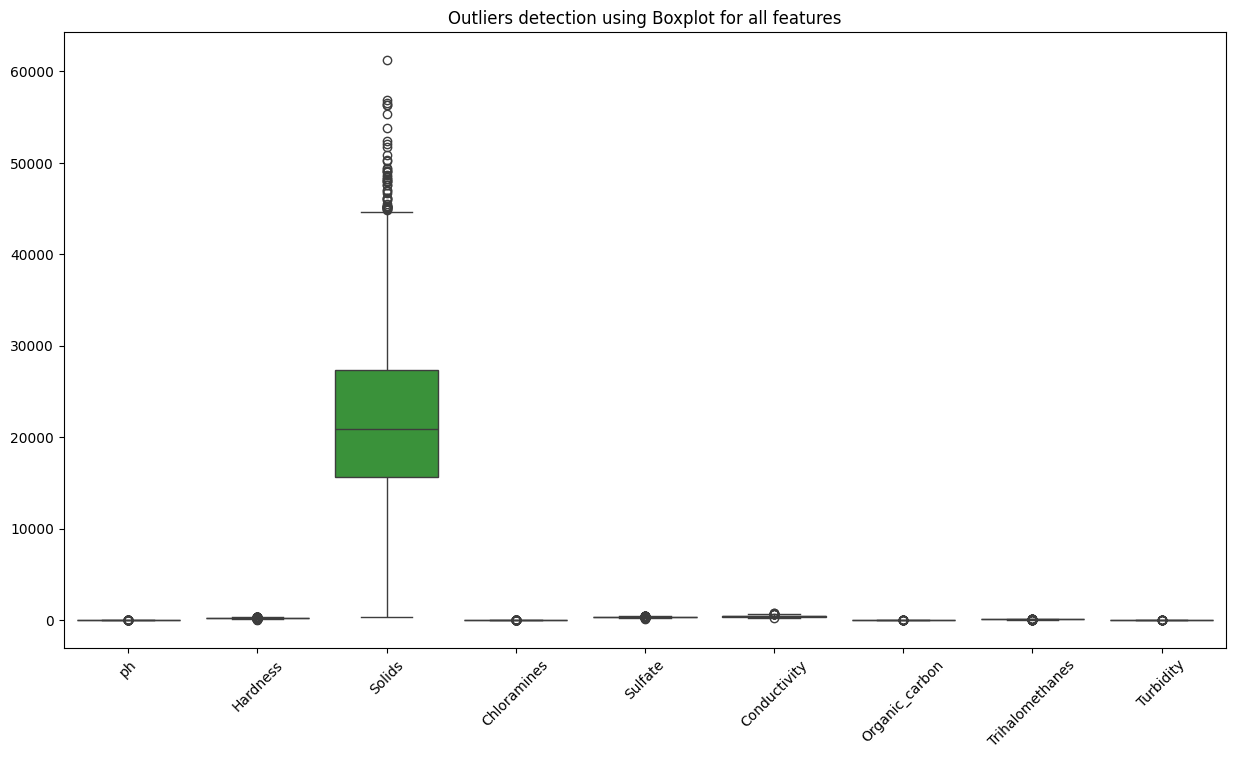

In [21]:
plt.figure(figsize=(15, 8))
sns.boxplot(data=data.drop(columns=['Potability']))
plt.xticks(rotation=45)
plt.title('Outliers detection using Boxplot for all features')
plt.show()

In [22]:
print("--- Skewness of Features ---")
print(data.skew(numeric_only=True))

print("\n--- Kurtosis of Features ---")
print(data.kurt(numeric_only=True))

--- Skewness of Features ---
ph                 0.025630
Hardness          -0.039342
Solids             0.621634
Chloramines       -0.012098
Sulfate           -0.035947
Conductivity       0.264490
Organic_carbon     0.025533
Trihalomethanes   -0.083031
Turbidity         -0.007817
Potability         0.450784
dtype: float64

--- Kurtosis of Features ---
ph                 0.720316
Hardness           0.615772
Solids             0.442826
Chloramines        0.589901
Sulfate            0.648263
Conductivity      -0.277093
Organic_carbon     0.044409
Trihalomethanes    0.238597
Turbidity         -0.062801
Potability        -1.797892
dtype: float64


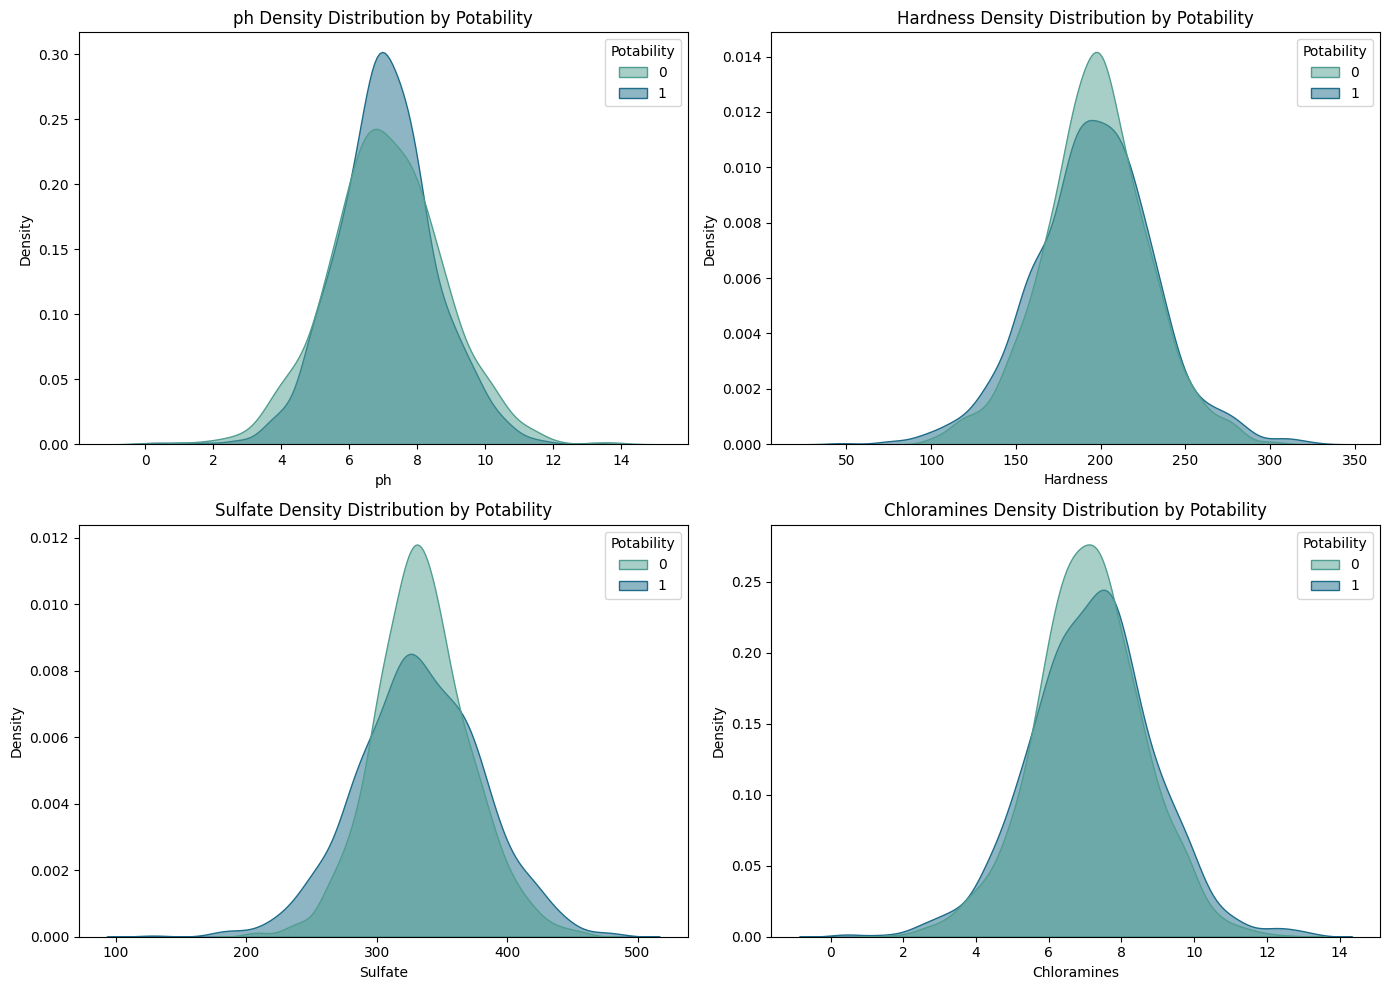

In [24]:
features_to_kde = ['ph', 'Hardness', 'Sulfate', 'Chloramines']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(features_to_kde):
    sns.kdeplot(data=data, x=col, hue='Potability', fill=True, common_norm=False, palette='crest', alpha=0.5, ax=axes[i])
    axes[i].set_title(f'{col} Density Distribution by Potability')

plt.tight_layout()
plt.show()

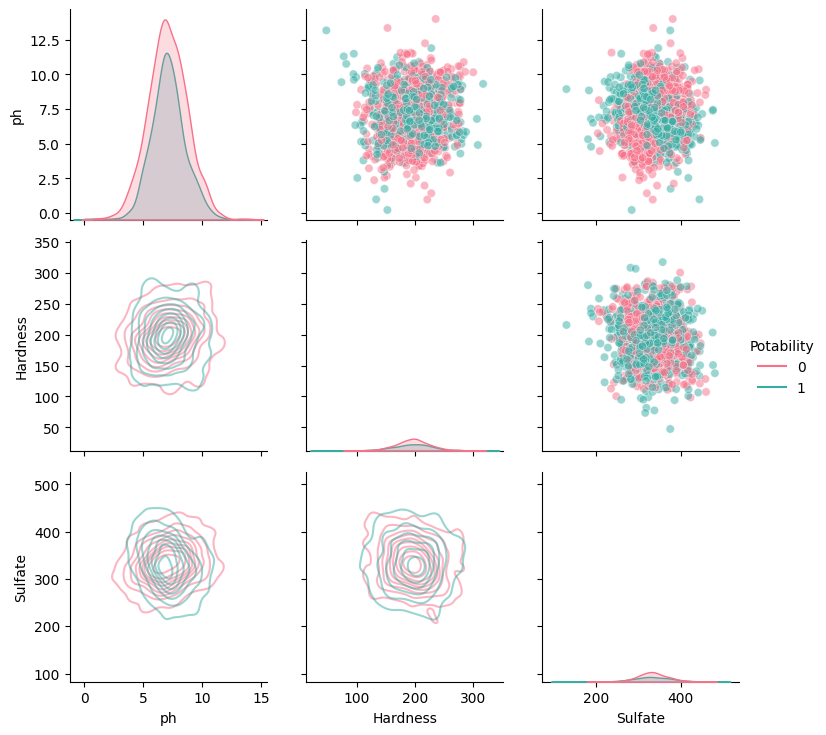

In [27]:
g = sns.PairGrid(data[['ph', 'Hardness', 'Sulfate', 'Potability']].dropna(), hue='Potability', palette='husl')
g.map_upper(sns.scatterplot, alpha=0.5)
g.map_diag(sns.kdeplot, fill=True)
g.map_lower(sns.kdeplot, alpha=0.5)
g.add_legend()
plt.show()

In [28]:
data_cleaned = data.copy()
for col in ['ph', 'Sulfate', 'Trihalomethanes']:
    median_val = data_cleaned[col].median()
    data_cleaned[col] = data_cleaned[col].fillna(median_val)

print("--- Missing values after imputation ---")
print(data_cleaned.isnull().sum())

display(data_cleaned.head())

--- Missing values after imputation ---
ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,7.036752,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,333.073546,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,333.073546,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
